Cell 1 — Imports

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

print("All libraries imported successfully.")

All libraries imported successfully.


Cell 2 — Load & Inspect Dataset


In [22]:

file_name = "Real estate valuation data set.xlsx"

df = pd.read_excel(file_name)

print("First 5 Rows:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

First 5 Rows:


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1



Dataset Shape:
(414, 8)

Column Names:
['No', 'X1 transaction date', 'X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 'X5 latitude', 'X6 longitude', 'Y house price of unit area']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit ar

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148953,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281995,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.666667,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.916667,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.166667,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.416667,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583333,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000



Duplicate Rows:
0


Cell 3 — Separate Features and Target


In [23]:
X = df[["X3 distance to the nearest MRT station"]]

y = df["Y house price of unit area"]

print("Input Feature:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)

Input Feature:
   X3 distance to the nearest MRT station
0                                84.87882
1                               306.59470
2                               561.98450
3                               561.98450
4                               390.56840

Target Variable:
0    37.9
1    42.2
2    47.3
3    54.8
4    43.1
Name: Y house price of unit area, dtype: float64

Input Shape: (414, 1)
Target Shape: (414,)


Cell 4 — Visualize the Dataset


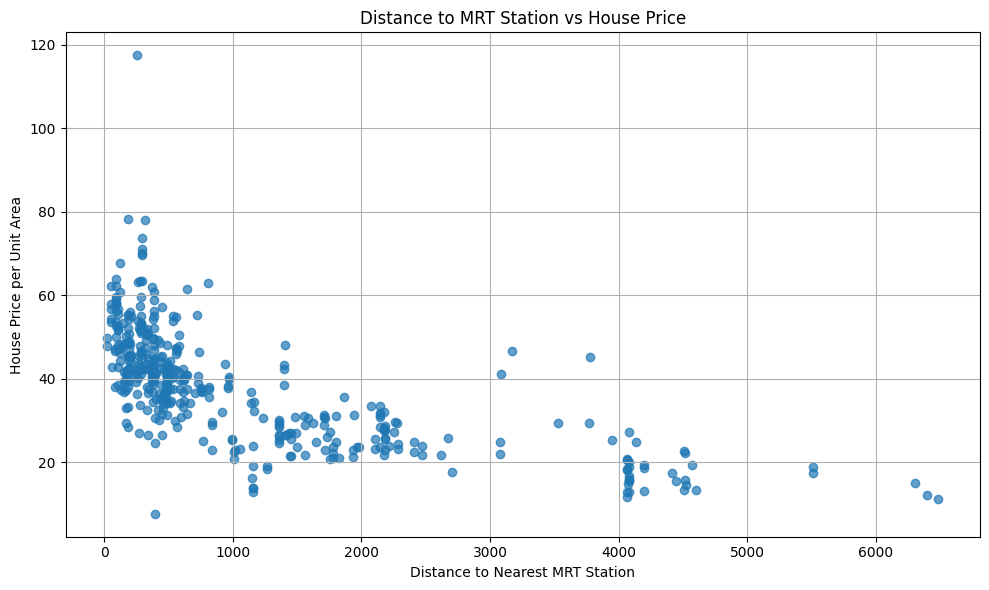

In [24]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X.iloc[:, 0],
    y,
    alpha=0.7
)

plt.xlabel("Distance to Nearest MRT Station")
plt.ylabel("House Price per Unit Area")

plt.title("Distance to MRT Station vs House Price")

plt.grid(True)
plt.tight_layout()
plt.show()

Cell 5 — Train/Test Split


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=27
)

print("Total Observations:", len(X))

print("\nTraining Observations:", len(X_train))
print("Testing Observations:", len(X_test))

print("\nTraining Input Shape:", X_train.shape)
print("Testing Input Shape:", X_test.shape)

Total Observations: 414

Training Observations: 331
Testing Observations: 83

Training Input Shape: (331, 1)
Testing Input Shape: (83, 1)


Cell 6 — Baseline Linear Regression


In [26]:
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


Cell 7 — Polynomial Models (Degrees 1–4)

In [27]:
degrees = [1, 2, 3, 4, 5]

models = {
    "Linear Regression": linear_model
}

for degree in degrees:

    model = Pipeline([
        ("scaler", StandardScaler()),
        (
            "polynomial",
            PolynomialFeatures(
                degree=degree,
                include_bias=False
            )
        ),
        ("regressor", LinearRegression())
    ])

    model.fit(X_train, y_train)

    models[f"Polynomial Degree {degree}"] = model

print("All regression models trained successfully.")

print("\nModels Created:")
for model_name in models:
    print(model_name)

All regression models trained successfully.

Models Created:
Linear Regression
Polynomial Degree 1
Polynomial Degree 2
Polynomial Degree 3
Polynomial Degree 4
Polynomial Degree 5


Cell 8 — Evaluate All Models


In [28]:
results = []

for model_name, model in models.items():

    # Predictions
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    # Training metrics
    train_r2 = r2_score(y_train, train_predictions)

    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_predictions)
    )

    # Testing metrics
    test_r2 = r2_score(y_test, test_predictions)

    test_mse = mean_squared_error(
        y_test,
        test_predictions
    )

    test_rmse = np.sqrt(test_mse)

    test_mae = mean_absolute_error(
        y_test,
        test_predictions
    )

    results.append({
        "Model": model_name,
        "Training R2": train_r2,
        "Test R2": test_r2,
        "Test MSE": test_mse,
        "Test RMSE": test_rmse,
        "Test MAE": test_mae
    })

results_df = pd.DataFrame(results)

print("Model Performance Comparison:\n")

display(
    results_df.round(4)
)

Model Performance Comparison:



,Model,Training R2,Test R2,Test MSE,Test RMSE,Test MAE
0,Linear Regression,0.4496,0.4534,91.8034,9.5814,7.4302
1,Polynomial Degree 1,0.4496,0.4534,91.8034,9.5814,7.4302
2,Polynomial Degree 2,0.5233,0.5268,79.4703,8.9146,6.7304
3,Polynomial Degree 3,0.5588,0.5281,79.2619,8.9029,6.8516
4,Polynomial Degree 4,0.5758,0.5105,82.2183,9.0674,7.0111
5,Polynomial Degree 5,0.5763,0.5093,82.4225,9.0787,7.0096


Cell 9 — Compare Training and Testing Performance

In [37]:
comparison = results_df[
    results_df["Model"].str.startswith("Polynomial Degree")
].copy()

comparison["Degree"] = comparison["Model"].str.extract(
    r"(\d+)"
).astype(int)

comparison["R2 Gap"] = (
    comparison["Training R2"] -
    comparison["Test R2"]
)

comparison = comparison.sort_values("Degree")

print("Training vs Testing R2 Comparison:\n")

display(
    comparison[
        [
            "Degree",
            "Training R2",
            "Test R2",
            "R2 Gap",
            "Test RMSE"
        ]
    ].round(4)
)

Training vs Testing R2 Comparison:



,Degree,Training R2,Test R2,R2 Gap,Test RMSE
1,1,0.4496,0.4534,-0.0038,9.5814
2,2,0.5233,0.5268,-0.0035,8.9146
3,3,0.5588,0.5281,0.0307,8.9029
4,4,0.5758,0.5105,0.0653,9.0674
5,5,0.5763,0.5093,0.0670,9.0787


Cell 10 — Five-Fold Cross-Validation


In [30]:
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for degree in degrees:

    model = models[f"Polynomial Degree {degree}"]

    scores = cross_val_score(
        model,
        X,
        y,
        cv=kf,
        scoring="r2"
    )

    cv_results.append({
        "Degree": degree,
        "Fold 1 R2": scores[0],
        "Fold 2 R2": scores[1],
        "Fold 3 R2": scores[2],
        "Fold 4 R2": scores[3],
        "Fold 5 R2": scores[4],
        "Mean CV R2": scores.mean(),
        "Std CV R2": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

print("Five-Fold Cross-Validation Results:\n")

display(
    cv_df.round(4)
)

best_cv_row = cv_df.loc[
    cv_df["Mean CV R2"].idxmax()
]

print("\nBest Degree Based on Mean Cross-Validation R2:")
print(int(best_cv_row["Degree"]))

print(
    "Mean Cross-Validation R2:",
    round(best_cv_row["Mean CV R2"], 4)
)

Five-Fold Cross-Validation Results:



,Degree,Fold 1 R2,Fold 2 R2,Fold 3 R2,Fold 4 R2,Fold 5 R2,Mean CV R2,Std CV R2
0,1,0.5390,0.3211,0.5449,0.4680,0.3601,0.4466,0.0915
1,2,0.5865,0.3603,0.6478,0.5389,0.4291,0.5125,0.1045
2,3,0.6352,0.4072,0.6900,0.5325,0.4580,0.5446,0.1057
3,4,0.6443,0.4205,0.7129,0.5289,0.4737,0.5561,0.1080
4,5,0.6281,0.4203,0.7083,0.5251,0.4743,0.5512,0.1042



Best Degree Based on Mean Cross-Validation R2:
4
Mean Cross-Validation R2: 0.5561


Cell 11 — Visualize Linear and Polynomial Regression

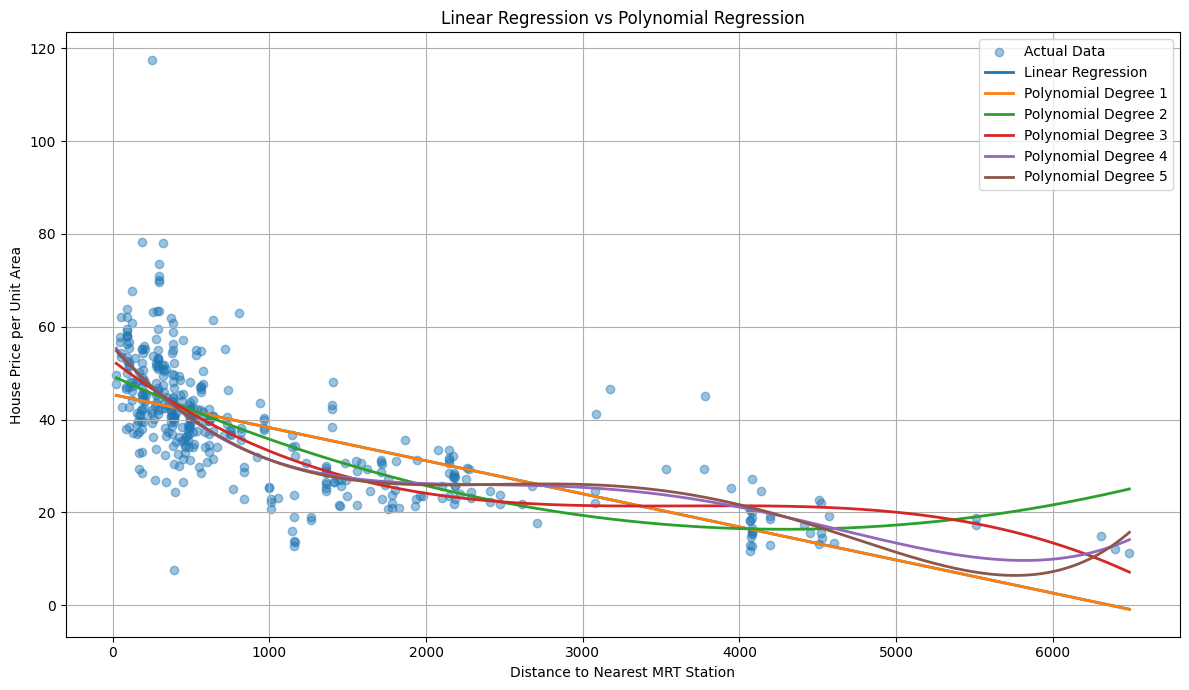

In [31]:
X_grid = pd.DataFrame({
    X.columns[0]: np.linspace(
        X.iloc[:, 0].min(),
        X.iloc[:, 0].max(),
        500
    )
})

plt.figure(figsize=(12, 7))

plt.scatter(
    X.iloc[:, 0],
    y,
    alpha=0.45,
    label="Actual Data"
)

for model_name, model in models.items():

    predictions = model.predict(X_grid)

    plt.plot(
        X_grid.iloc[:, 0],
        predictions,
        label=model_name,
        linewidth=2
    )

plt.xlabel("Distance to Nearest MRT Station")
plt.ylabel("House Price per Unit Area")

plt.title(
    "Linear Regression vs Polynomial Regression"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Cell 12 — Visualize Cross-Validation Performance

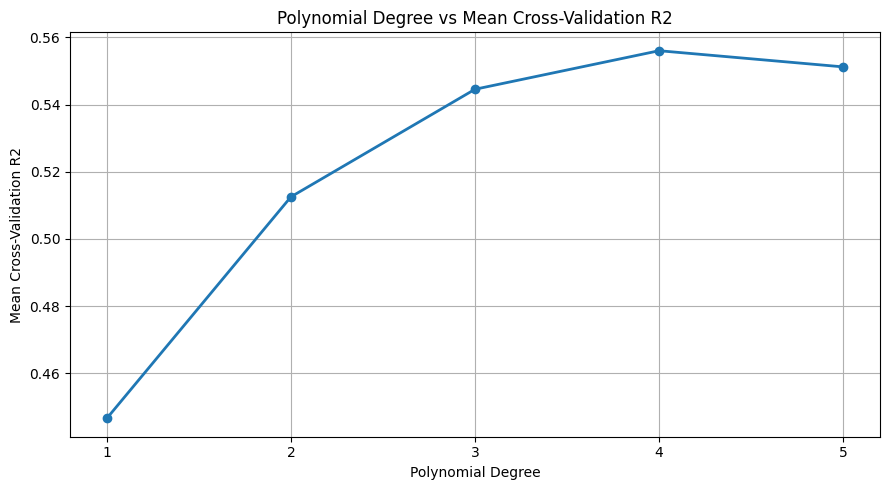

In [32]:
plt.figure(figsize=(9, 5))

plt.plot(
    cv_df["Degree"],
    cv_df["Mean CV R2"],
    marker="o",
    linewidth=2
)

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Cross-Validation R2")

plt.title(
    "Polynomial Degree vs Mean Cross-Validation R2"
)

plt.xticks(degrees)
plt.grid(True)
plt.tight_layout()
plt.show()

Cell 13 — Display the Best Model and Its Polynomial Equation

In [33]:
best_degree = int(
    cv_df.loc[
        cv_df["Mean CV R2"].idxmax(),
        "Degree"
    ]
)

best_model = models[
    f"Polynomial Degree {best_degree}"
]

print("Best Polynomial Degree:", best_degree)

print(
    "Mean Cross-Validation R2:",
    round(
        cv_df.loc[
            cv_df["Degree"] == best_degree,
            "Mean CV R2"
        ].iloc[0],
        4
    )
)

# Get the fitted preprocessing and regression components
scaler = best_model.named_steps["scaler"]
poly = best_model.named_steps["polynomial"]
regressor = best_model.named_steps["regressor"]

coefficients = regressor.coef_
intercept = regressor.intercept_

print("\nPolynomial Equation")
print(
    "Note: z is the standardized distance to the nearest MRT station."
)

equation = f"Predicted House Price = {intercept:.6f}"

for power, coefficient in enumerate(coefficients, start=1):

    sign = "+" if coefficient >= 0 else "-"

    equation += (
        f" {sign} {abs(coefficient):.6f} * z^{power}"
    )

print(equation)

Best Polynomial Degree: 4
Mean Cross-Validation R2: 0.5561

Polynomial Equation
Note: z is the standardized distance to the nearest MRT station.
Predicted House Price = 30.188518 - 12.712756 * z^1 + 14.227865 * z^2 - 6.614109 * z^3 + 0.889884 * z^4


Cell 14 — Predict a New House Price

In [34]:
new_distance = float(
    input("Enter distance to the nearest MRT station: ")
)

# Create input DataFrame using the correct feature name
new_data = pd.DataFrame({
    X.columns[0]: [new_distance]
})

print("\nPredicted House Prices")
print("=" * 55)

for model_name, model in models.items():

    predicted_price = model.predict(new_data)[0]

    print(
        f"{model_name}: "
        f"{predicted_price:.2f}"
    )

Enter distance to the nearest MRT station: 500

Predicted House Prices
Linear Regression: 41.83
Polynomial Degree 1: 41.83
Polynomial Degree 2: 42.12
Polynomial Degree 3: 41.43
Polynomial Degree 4: 40.10
Polynomial Degree 5: 40.31


Cell 15 — Check Underfitting and Overfitting

In [35]:
diagnostics = []

for model_name, model in models.items():

    # Predictions on training and testing data
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    # Calculate R2 scores
    train_r2 = r2_score(y_train, train_predictions)
    test_r2 = r2_score(y_test, test_predictions)

    # Calculate RMSE values
    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_predictions)
    )

    test_rmse = np.sqrt(
        mean_squared_error(y_test, test_predictions)
    )

    # Calculate generalization gap
    r2_gap = train_r2 - test_r2

    # ---- Improved diagnostic interpretation ----
    if train_r2 < 0.50 and test_r2 < 0.50:
        diagnosis = "Possible Underfitting"

    elif r2_gap > 0.15:
        diagnosis = "Possible Overfitting"

    elif r2_gap < -0.15:
        diagnosis = "Test Outperformed Train (Sampling Artifact)"

    elif abs(r2_gap) <= 0.15 and test_r2 >= 0.60:
        diagnosis = "Good Generalization"

    elif abs(r2_gap) <= 0.15 and test_r2 < 0.60:
        diagnosis = "Reasonable but Weak Fit"

    else:
        diagnosis = "No Strong Warning from These Rules"

    diagnostics.append({
        "Model": model_name,
        "Training R2": train_r2,
        "Testing R2": test_r2,
        "R2 Gap": r2_gap,
        "Training RMSE": train_rmse,
        "Testing RMSE": test_rmse,
        "Initial Diagnosis": diagnosis
    })

diagnostics_df = pd.DataFrame(diagnostics)

print("Underfitting and Overfitting Analysis\n")

display(
    diagnostics_df.round(4)
)

Underfitting and Overfitting Analysis



,Model,Training R2,Testing R2,R2 Gap,Training RMSE,Testing RMSE,Initial Diagnosis
0,Linear Regression,0.4496,0.4534,-0.0038,10.1646,9.5814,Possible Underfitting
1,Polynomial Degree 1,0.4496,0.4534,-0.0038,10.1646,9.5814,Possible Underfitting
2,Polynomial Degree 2,0.5233,0.5268,-0.0035,9.4596,8.9146,Reasonable but Weak Fit
3,Polynomial Degree 3,0.5588,0.5281,0.0307,9.1009,8.9029,Reasonable but Weak Fit
4,Polynomial Degree 4,0.5758,0.5105,0.0653,8.9240,9.0674,Reasonable but Weak Fit
5,Polynomial Degree 5,0.5763,0.5093,0.0670,8.9183,9.0787,Reasonable but Weak Fit


Cell 16 — Visualize Training vs Testing R²

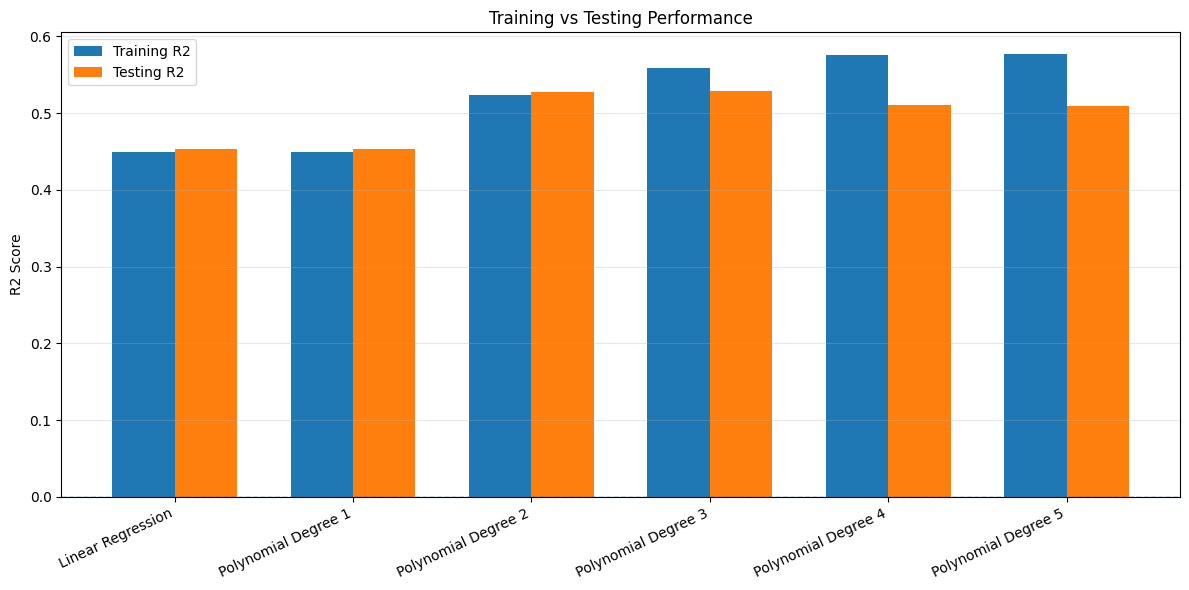

In [36]:
x_positions = np.arange(len(diagnostics_df))
bar_width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x_positions - bar_width / 2,
    diagnostics_df["Training R2"],
    bar_width,
    label="Training R2"
)

plt.bar(
    x_positions + bar_width / 2,
    diagnostics_df["Testing R2"],
    bar_width,
    label="Testing R2"
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.xticks(
    x_positions,
    diagnostics_df["Model"],
    rotation=25,
    ha="right"
)

plt.ylabel("R2 Score")
plt.title("Training vs Testing Performance")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()